In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q1_d.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

faces = fetch_olivetti_faces(shuffle=False)
X = faces.images
y = faces.target

height = X.shape[1]
width = X.shape[2]

split_data = np.load("olivetti_split_indices.npz")

train_idx = split_data["train"]
val_idx = split_data["val"]
test_idx = split_data["test"]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

X_test_corrupted = X_test.copy()
X_test_corrupted[:, 24:40, 24:40] = 0.0

logger.info(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
logger.info(f"X_val:   {X_val.shape}, y_val:   {y_val.shape}")
logger.info(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
logger.info(f"X_test_corrupted:  {X_test_corrupted.shape}, y_test:  {y_test.shape}")




X_train = X_train.reshape(-1, height * width)
X_val = X_val.reshape(-1, height * width)
X_test = X_test.reshape(-1, height * width)
X_test_corrupted = X_test_corrupted.reshape(-1, height * width)

seed = 260007
rng = np.random.default_rng(seed=seed)
n_train = len(X_train)
B_final = 200

single_tree = DecisionTreeClassifier(max_depth=None, min_samples_leaf=2, random_state=seed)
single_tree.fit(X_train, y_train)

tree_pred_clean = single_tree.predict(X_test)
tree_pred_corrupt = single_tree.predict(X_test_corrupted)

tree_acc_clean = np.mean(tree_pred_clean == y_test)
tree_acc_corrupt = np.mean(tree_pred_corrupt == y_test)

tree_prob_clean = single_tree.predict_proba(X_test)
tree_prob_corrupt = single_tree.predict_proba(X_test_corrupted)
sample_conf_clean = np.max(tree_prob_clean, axis=1)
sample_conf_corrupt = np.max(tree_prob_corrupt, axis=1)
tree_conf_clean = np.mean(sample_conf_clean)
tree_conf_corrupt = np.mean(sample_conf_corrupt)

ensemble_trees = []
for b in range(B_final):
    boot_idx = rng.choice(n_train, size=n_train, replace=True)
    clf = DecisionTreeClassifier(max_depth=None, min_samples_leaf=2, random_state=seed + b)
    clf.fit(X_train[boot_idx], y_train[boot_idx])
    ensemble_trees.append(clf)

clean_preds_matrix = np.array([tree.predict(X_test) for tree in ensemble_trees])
corrupt_preds_matrix = np.array([tree.predict(X_test_corrupted) for tree in ensemble_trees])

def evaluate_ensemble(preds_matrix, y_true):
    N = preds_matrix.shape[1]
    final_preds = np.zeros(N, dtype=int)
    confidences = np.zeros(N, dtype=float)
    
    for i in range(N):
        votes = preds_matrix[:, i]
        classes, counts = np.unique(votes, return_counts=True)
        winning_idx = np.argmax(counts)
        
        final_preds[i] = classes[winning_idx]
        confidences[i] = counts[winning_idx] / len(votes)
        
    accuracy = np.mean(final_preds == y_true)
    mean_confidence = np.mean(confidences)
    return final_preds, confidences, accuracy, mean_confidence

bag_pred_clean, bag_conf_clean_arr, bag_acc_clean, bag_conf_clean = evaluate_ensemble(clean_preds_matrix, y_test)
bag_pred_corrupt, bag_conf_corrupt_arr, bag_acc_corrupt, bag_conf_corrupt = evaluate_ensemble(corrupt_preds_matrix, y_test)

logger.info("=" * 80)
logger.info(f"PERFORMANCE COMPARISON: FROZEN SINGLE TREE vs BAGGING (B={B_final})")
logger.info("=" * 80)
logger.info(f"{'Model':<20} | {'Clean Test Acc':<15} | {'Clean Conf':<12} | {'Corrupt Test Acc':<16} | {'Corrupt Conf':<12}")
logger.info("-" * 80)
logger.info(f"{'Single Tree':<20} | {tree_acc_clean:<15.4f} | {tree_conf_clean:<12.4f} | {tree_acc_corrupt:<16.4f} | {tree_conf_corrupt:<12.4f}")
logger.info(f"{'Bagging (B=' + str(B_final) + ')':<20} | {bag_acc_clean:<15.4f} | {bag_conf_clean:<12.4f} | {bag_acc_corrupt:<16.4f} | {bag_conf_corrupt:<12.4f}")
logger.info("=" * 80)

# corrected_indices = np.where((tree_pred_corrupt != y_test) & (bag_pred_corrupt == y_test))[0]
# both_wrong_indices = np.where((tree_pred_corrupt != y_test) & (bag_pred_corrupt != y_test))[0]

# logger.info("\n--- CASE A: Bagging Corrects Single Tree (2 Examples) ---")
# for idx in corrected_indices[:2]:
#     votes = corrupt_preds_matrix[:, idx]
#     classes, counts = np.unique(votes, return_counts=True)
#     sorted_order = np.argsort(counts)[::-1]
#     vote_summary = {classes[k]: counts[k] for k in sorted_order[:3]}
    
#     logger.info(f"Sample Index {idx}: True Class = {y_test[idx]} | Single Tree Pred = {tree_pred_corrupt[idx]} | Bagging Pred = {bag_pred_corrupt[idx]}")
#     logger.info(f"  Top Vote Counts (Out of {B_final}): {vote_summary}\n")

# logger.info("--- CASE B: Both Single Tree and Bagging are WRONG (2 Examples) ---")
# for idx in both_wrong_indices[:2]:
#     votes = corrupt_preds_matrix[:, idx]
#     classes, counts = np.unique(votes, return_counts=True)
#     sorted_order = np.argsort(counts)[::-1]
#     vote_summary = {classes[k]: counts[k] for k in sorted_order[:3]}
    
#     logger.info(f"Sample Index {idx}: True Class = {y_test[idx]} | Single Tree Pred = {tree_pred_corrupt[idx]} | Bagging Pred = {bag_pred_corrupt[idx]}")
#     logger.info(f"  Top Vote Counts (Out of {B_final}): {vote_summary}\n")

X_train: (240, 64, 64), y_train: (240,)
X_val:   (80, 64, 64), y_val:   (80,)
X_test:  (80, 64, 64), y_test:  (80,)
X_test_corrupted:  (80, 64, 64), y_test:  (80,)
PERFORMANCE COMPARISON: FROZEN SINGLE TREE vs BAGGING (B=200)
Model                | Clean Test Acc  | Clean Conf   | Corrupt Test Acc | Corrupt Conf
--------------------------------------------------------------------------------
Single Tree          | 0.6500          | 0.9750       | 0.3500           | 1.0000      
Bagging (B=200)      | 0.8500          | 0.4117       | 0.6375           | 0.2697      


CASE STUDY: 2 FACES WHERE BAGGING CORRECTS THE TREE
Test Face Index: 1
  - True Label:         39
  - Single Tree Pred:   12
  - Bagging Majority:   39
  - Bagging Vote Breakdown (Class: Votes): {np.int64(0): np.int64(5), np.int64(1): np.int64(1), np.int64(3): np.int64(9), np.int64(4): np.int64(3), np.int64(6): np.int64(2), np.int64(7): np.int64(7), np.int64(8): np.int64(11), np.int64(9): np.int64(8), np.int64(11): np.int64(2), np.int64(12): np.int64(10), np.int64(13): np.int64(1), np.int64(14): np.int64(10), np.int64(15): np.int64(5), np.int64(16): np.int64(6), np.int64(17): np.int64(20), np.int64(20): np.int64(16), np.int64(21): np.int64(1), np.int64(22): np.int64(8), np.int64(23): np.int64(1), np.int64(24): np.int64(7), np.int64(25): np.int64(1), np.int64(26): np.int64(1), np.int64(27): np.int64(2), np.int64(28): np.int64(7), np.int64(29): np.int64(1), np.int64(30): np.int64(3), np.int64(32): np.int64(4), np.int64(34): np.int64(10), np.int64(35): np.int64(1), np.int64(38): np.int64(

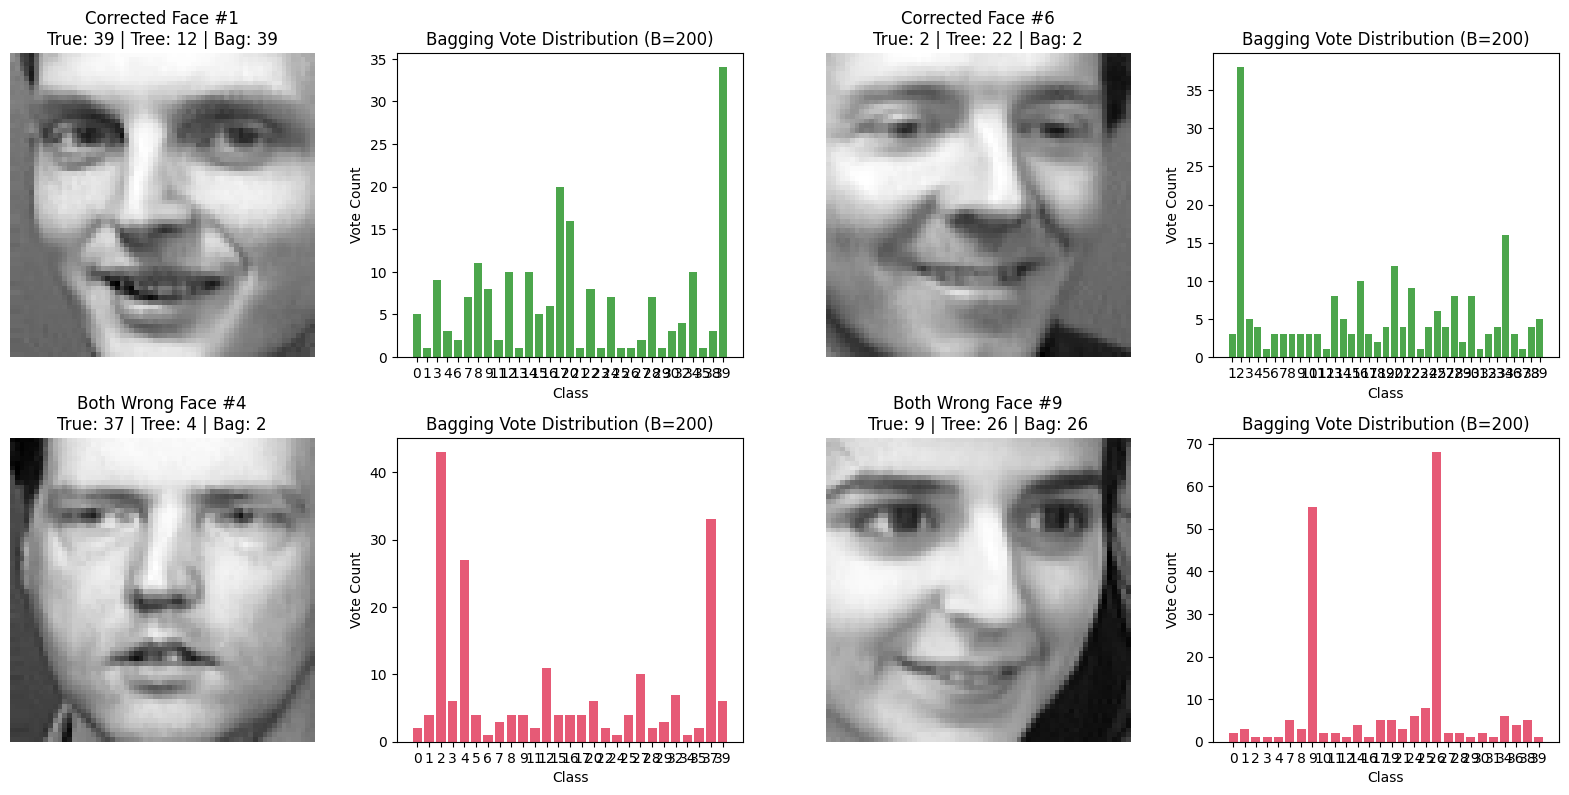

In [2]:
corrected_indices = []
both_wrong_indices = []

for i in range(len(y_test)):
    t_pred = tree_pred_clean[i]
    b_pred = bag_pred_clean[i]
    actual = y_test[i]
    
    if t_pred != actual and b_pred == actual:
        corrected_indices.append(i)
    elif t_pred != actual and b_pred != actual:
        both_wrong_indices.append(i)

two_corrected = corrected_indices[:2]
two_both_wrong = both_wrong_indices[:2]

def print_case_details(indices, case_title):
    logger.info("=" * 80)
    logger.info(f"CASE STUDY: {case_title}")
    logger.info("=" * 80)
    for idx in indices:
        actual = y_test[idx]
        t_pred = tree_pred_clean[idx]
        b_pred = bag_pred_clean[idx]
        
        votes = clean_preds_matrix[:, idx]
        unique_cls, counts = np.unique(votes, return_counts=True)
        vote_dict = dict(zip(unique_cls, counts))
        
        logger.info(f"Test Face Index: {idx}")
        logger.info(f"  - True Label:         {actual}")
        logger.info(f"  - Single Tree Pred:   {t_pred}")
        logger.info(f"  - Bagging Majority:   {b_pred}")
        logger.info(f"  - Bagging Vote Breakdown (Class: Votes): {vote_dict}")
        logger.info("-" * 50)

print_case_details(two_corrected, "2 FACES WHERE BAGGING CORRECTS THE TREE")
print_case_details(two_both_wrong, "2 FACES WHERE BOTH SINGLE TREE AND BAGGING ARE WRONG")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for col, idx in enumerate(two_corrected):
    actual = y_test[idx]
    t_pred = tree_pred_clean[idx]
    b_pred = bag_pred_clean[idx]
    
    axes[0, col*2].imshow(X_test[idx].reshape(height, width), cmap="gray")
    axes[0, col*2].set_title(f"Corrected Face #{idx}\nTrue: {actual} | Tree: {t_pred} | Bag: {b_pred}")
    axes[0, col*2].axis("off")
    
    votes = clean_preds_matrix[:, idx]
    unique_cls, counts = np.unique(votes, return_counts=True)
    axes[0, col*2 + 1].bar([str(c) for c in unique_cls], counts, color="green", alpha=0.7)
    axes[0, col*2 + 1].set_title(f"Bagging Vote Distribution (B={B_final})")
    axes[0, col*2 + 1].set_xlabel("Class")
    axes[0, col*2 + 1].set_ylabel("Vote Count")

for col, idx in enumerate(two_both_wrong):
    actual = y_test[idx]
    t_pred = tree_pred_clean[idx]
    b_pred = bag_pred_clean[idx]
    
    axes[1, col*2].imshow(X_test[idx].reshape(height, width), cmap="gray")
    axes[1, col*2].set_title(f"Both Wrong Face #{idx}\nTrue: {actual} | Tree: {t_pred} | Bag: {b_pred}")
    axes[1, col*2].axis("off")
    
    votes = clean_preds_matrix[:, idx]
    unique_cls, counts = np.unique(votes, return_counts=True)
    axes[1, col*2 + 1].bar([str(c) for c in unique_cls], counts, color="crimson", alpha=0.7)
    axes[1, col*2 + 1].set_title(f"Bagging Vote Distribution (B={B_final})")
    axes[1, col*2 + 1].set_xlabel("Class")
    axes[1, col*2 + 1].set_ylabel("Vote Count")

plt.tight_layout()

plt.savefig("q1_d_bagging_breakdown.png", dpi=300, bbox_inches="tight")

plt.show()